In [1]:
# Import Necessary Libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

I0000 00:00:1792079068.664746   16406 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792079068.665256   16406 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792079068.711936   16406 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792079070.325949   16406 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Libraries imported successfully


In [5]:
# Load Breast Cancer Dataset

df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)
print(df.head())# Load Breast Cancer Dataset


Dataset loaded successfully
Dataset Shape: (569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  t

In [6]:
# Prepare Input and Output Data

X = df.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32'],
    errors='ignore'
)

y = df['diagnosis'].map({'M': 1, 'B': 0})

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)
print("Data prepared successfully")

Input Shape: (569, 30)
Output Shape: (569,)
Data prepared successfully


In [7]:
# Split Dataset into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)


In [8]:
# Normalize Input Data

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data normalization completed successfully")

Data normalization completed successfully


In [9]:
# Create Artificial Neural Network

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

print("Deep learning model created successfully")

Deep learning model created successfully


E0000 00:00:1792079380.784135   16406 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [10]:
# Compile the Model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully")

Model compiled successfully


In [11]:
# Train the Deep Learning Model

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("Model training completed successfully")

Epoch 1/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6538 - loss: 0.5990 - val_accuracy: 0.8242 - val_loss: 0.4801
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8599 - loss: 0.3672 - val_accuracy: 0.9231 - val_loss: 0.3281
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9258 - loss: 0.2678 - val_accuracy: 0.9341 - val_loss: 0.2447
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9451 - loss: 0.1953 - val_accuracy: 0.9341 - val_loss: 0.2003
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9423 - loss: 0.1592 - val_accuracy: 0.9451 - val_loss: 0.1701
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9533 - loss: 0.1274 - val_accuracy: 0.9451 - val_loss: 0.1540
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9780 - loss: 0.1051 - val_accuracy: 0.9560 - val_loss: 0.1445
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9753 - loss: 0.0929 - val_accuracy: 0.9670 - val_loss

In [12]:
# Evaluate the Model

loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Loss: 0.07891914993524551
Test Accuracy: 0.9824561476707458
Test Accuracy (%): 98.24561476707458


In [13]:
# Generate Predictions

y_pred_probability = model.predict(X_test)

y_pred = (y_pred_probability > 0.5).astype(int).flatten()

comparison = pd.DataFrame({
    'Actual': y_test.to_numpy(),
    'Predicted': y_pred
})

print(comparison.head(10))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
   Actual  Predicted
0       0          0
1       1          1
2       0          0
3       1          1
4       0          0
5       0          0
6       1          1
7       0          0
8       0          0
9       0          0


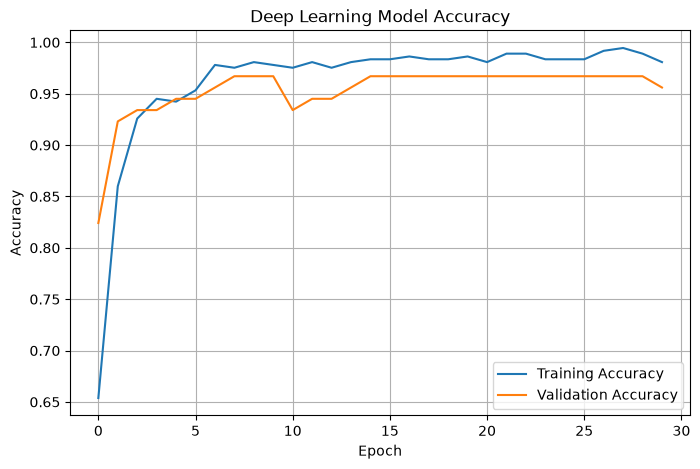

In [14]:
# Plot Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Deep Learning Model Accuracy')
plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Display Final Model Performance

print("Deep Learning Application Results")
print("---------------------------------")
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)
print("Model prediction completed successfully")

Deep Learning Application Results
---------------------------------
Test Loss: 0.07891914993524551
Test Accuracy: 0.9824561476707458
Test Accuracy (%): 98.24561476707458
Model prediction completed successfully


In [16]:
# Breast Cancer Classification Application

def predict_breast_cancer(features):

    features = np.array(features).reshape(1, -1)

    features_scaled = scaler.transform(features)

    probability = model.predict(
        features_scaled,
        verbose=0
    )[0][0]

    if probability >= 0.5:
        result = "Malignant"
        confidence = probability * 100
    else:
        result = "Benign"
        confidence = (1 - probability) * 100

    return result, confidence


print("Breast Cancer Classification Application Ready")

Breast Cancer Classification Application Ready


In [17]:
# Test the Application with a Dataset Record

sample_features = df.drop(
    columns=['id', 'diagnosis', 'Unnamed: 32'],
    errors='ignore'
).iloc[0].values

actual_diagnosis = df['diagnosis'].iloc[0]

prediction, confidence = predict_breast_cancer(
    sample_features
)

print("Breast Cancer Classification Result")
print("------------------------------------")
print("Actual Diagnosis:", actual_diagnosis)
print("Predicted Diagnosis:", prediction)
print("Model Confidence: {:.2f}%".format(confidence))

Breast Cancer Classification Result
------------------------------------
Actual Diagnosis: M
Predicted Diagnosis: Malignant
Model Confidence: 100.00%


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
